# 07_ROCOv2_VLM_Training — Proposed VLM

**Purpose:** Train the thesis's proposed model — a fine-tuned BiomedCLIP
with a trained multi-label classification head on the fused image+caption
embedding. This is the notebook that follows the DenseNet121 baseline (05)
and the BiomedCLIP zero-shot baseline (06), and everything downstream
(conformal prediction, counterfactuals, trust score) builds on whatever
model comes out of this notebook.

### Architecture (confirmed, not assumed)
- **Backbone:** the same fixed BiomedCLIP checkpoint as Notebook 06
  (`hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224`),
  fine-tuned (both vision and text towers unfrozen in Stage 2).
- **Fusion:** each sample's image embedding and its own caption's text
  embedding (both L2-normalized) are concatenated and passed through a new,
  trained classification head (`Linear -> ReLU -> Dropout -> Linear -> 18
  logits`). `BCEWithLogitsLoss`, sigmoid at eval — multi-label, no softmax,
  same convention as Notebooks 05/06.
- **Modality at inference:** **image + caption, at both train and test
  time** — a genuinely multimodal system end to end.

### METHODOLOGICAL CAVEAT — read before interpreting any result below
The model receives each sample's **ground-truth ROCOv2 caption as an
input feature**, including at Test time. ROCOv2 captions frequently
describe the imaging modality/anatomy/view directly (e.g., a caption
mentioning "CT of the abdomen" for a sample labeled CT + Abdomen) — the
same information the 18 labels represent. This means Test results in this
notebook should be read as a **caption-assisted upper-bound scenario**,
not a pure image-only diagnostic setting comparable to Notebook 05's
DenseNet121 baseline. This was a deliberate, explicit design choice (not
an oversight) made to match this thesis's "Vision-Language Model" framing
end-to-end; it is restated in the final report below so it can't be missed
when reading results out of context.

### What this notebook does NOT do
No conformal prediction, no calibration split, no counterfactual/XAI, no
trust score. No modification of Notebooks 01–06 or the original ROCOv2
files. No use of Test for anything except the single, final, frozen
evaluation.

### Inputs
- `Prepared/train_prepared.csv`, `validation_prepared.csv`,
  `test_prepared.csv`, `label_mapping.json` (Notebook 02).
- Original ROCOv2 Train/Validation/Test image ZIPs (read-only).
- **Not** Notebook 04's `preprocessing_config.json` — same deliberate
  deviation as Notebook 06: BiomedCLIP requires its own pretrained image
  transform and tokenizer.

### Outputs
18 artifacts under `Prepared/Baselines/BiomedCLIP_VLM_Trained/`: config,
training history, validation/test/per-label metrics, predictions, both
checkpoints, learning-curve/ROC/PR/confusion-matrix figures (vector PDF +
300 DPI PNG), `reproducibility.json`, `artifact_manifest.json`.

### Split roles (unchanged protocol)
- **Train** — model training and every statistic fit here (class-imbalance
  weighting).
- **Validation** — early stopping, checkpoint selection, development only.
  Not a Calibration set (see the explicit warning near the end).
- **Test** — loaded once, at the end, for final evaluation only.

### Resumability
Same design as Notebook 05: an existing checkpoint in this baseline
directory is resumed from by default (weights, epoch, early-stopping
state, history all restored), never silently discarded. Training history
is written incrementally, per epoch, not just at the end.

In [ ]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import os
import io
import sys
import json
import time
import random
import shutil
import zipfile
import warnings
import platform
import subprocess
import itertools
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

# ------------------------------------------------------------
# MULTI-SEED EXPERIMENT -- output directory for this run.
# Original single-seed (reference) value, DO NOT reuse for a new seed run:
#   BASELINE_DIR = PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_Trained"
# Active configuration for THIS run (must match SEED below):
#   Seed 123  -> BiomedCLIP_VLM_Trained_seed123
#   Seed 2024 -> BiomedCLIP_VLM_Trained_seed2024
#   Seed 3407 -> BiomedCLIP_VLM_Trained_seed3407
#   Seed 7777 -> BiomedCLIP_VLM_Trained_seed7777
# ------------------------------------------------------------
BASELINE_DIR = PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_Trained_seed2024"
CKPT_DIR = BASELINE_DIR / "checkpoints"
FIG_DIR = BASELINE_DIR / "figures"
for d in [BASELINE_DIR, CKPT_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TRAIN_PREPARED_PATH = PREPARED_DIR / "train_prepared.csv"
VALID_PREPARED_PATH = PREPARED_DIR / "validation_prepared.csv"
TEST_PREPARED_PATH = PREPARED_DIR / "test_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"

IMAGE_ZIP_FILES = {
    "train": ROCO_ROOT / "Train" / "Images" / "train_images.zip",
    "validation": ROCO_ROOT / "Validation" / "Images" / "valid_images.zip",
    "test": ROCO_ROOT / "Test" / "Images" / "test_images.zip",
}

CONFIG_PATH = BASELINE_DIR / "vlm_config.json"
HISTORY_PATH = BASELINE_DIR / "vlm_training_history.csv"
VAL_METRICS_PATH = BASELINE_DIR / "vlm_validation_metrics.csv"
TEST_METRICS_PATH = BASELINE_DIR / "vlm_test_metrics.csv"
PER_LABEL_METRICS_PATH = BASELINE_DIR / "vlm_per_label_metrics.csv"
PREDICTIONS_PATH = BASELINE_DIR / "vlm_predictions.csv"
BEST_MODEL_PATH = CKPT_DIR / "vlm_best_model.pt"
LAST_MODEL_PATH = CKPT_DIR / "vlm_last_model.pt"
LEARNING_CURVES_PDF = FIG_DIR / "learning_curves.pdf"
LEARNING_CURVES_PNG = FIG_DIR / "learning_curves_300dpi.png"
ROC_CURVES_PDF = FIG_DIR / "roc_curves.pdf"
ROC_CURVES_PNG = FIG_DIR / "roc_curves_300dpi.png"
PR_CURVES_PDF = FIG_DIR / "precision_recall_curves.pdf"
PR_CURVES_PNG = FIG_DIR / "precision_recall_curves_300dpi.png"
CM_PDF = FIG_DIR / "multilabel_confusion_matrices.pdf"
CM_PNG = FIG_DIR / "multilabel_confusion_matrices_300dpi.png"
REPRODUCIBILITY_PATH = BASELINE_DIR / "reproducibility.json"
MANIFEST_PATH = BASELINE_DIR / "artifact_manifest.json"
CORRUPT_SAMPLE_LOG_PATH = BASELINE_DIR / "corrupt_samples_skipped_during_training.jsonl"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

# ------------------------------------------------------------
# MULTI-SEED EXPERIMENT -- active seed for this run.
# Original single-seed (reference) value, DO NOT reuse for a new seed run: SEED = 42
# Must match the BASELINE_DIR suffix set above. Seed/directory pairs for
# this experiment: 123, 2024, 3407, 7777 (42 is the existing reference,
# retrained only if explicitly decided later -- see MULTISEED_EXPERIMENT_PLAN.md).
# ------------------------------------------------------------
SEED = 2024

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed(seed)
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_global_seed(SEED)

print("=" * 80)
print("NOTEBOOK 07 — VLM TRAINING (FINE-TUNED BIOMEDCLIP)")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("BASELINE_DIR:", BASELINE_DIR)
print("Random seed:", SEED)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive available.
NOTEBOOK 07 — VLM TRAINING (FINE-TUNED BIOMEDCLIP)
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
BASELINE_DIR: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024
Random seed: 2024


## 1. Verify required inputs from Notebook 02

In [ ]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "train_prepared.csv": TRAIN_PREPARED_PATH,
    "validation_prepared.csv": VALID_PREPARED_PATH,
    "test_prepared.csv": TEST_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
}

missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 07 input artifacts are missing:\n\n" + "\n".join(missing_inputs)
        + "\n\nRun 02_ROCOv2_Dataset_Preparation.ipynb first."
    )

for name, path in IMAGE_ZIP_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Original image ZIP missing for {name}: {path}")

print("PASS — Required Notebook 02 artifacts and original image ZIPs exist.")
for name, path in required_inputs.items():
    print(f"{name:30s}: {path}")


PASS — Required Notebook 02 artifacts and original image ZIPs exist.
train_prepared.csv            : /content/drive/MyDrive/ROCOv2/Prepared/train_prepared.csv
validation_prepared.csv       : /content/drive/MyDrive/ROCOv2/Prepared/validation_prepared.csv
test_prepared.csv             : /content/drive/MyDrive/ROCOv2/Prepared/test_prepared.csv
label_mapping.json            : /content/drive/MyDrive/ROCOv2/Prepared/label_mapping.json


## 2. Load the authoritative split, label taxonomy, and captions

`Caption` is read directly from the prepared CSVs (Notebook 02 already
verified every caption is non-empty).

In [ ]:
# ============================================================
# CELL 3 — LOAD SPLITS AND LABEL MAPPING
# ============================================================

split_dfs = {
    "train": pd.read_csv(TRAIN_PREPARED_PATH),
    "validation": pd.read_csv(VALID_PREPARED_PATH),
    "test": pd.read_csv(TEST_PREPARED_PATH),
}

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

assert len(label_mapping) == 18, "Authoritative label_mapping.json must contain exactly 18 labels."
LABEL_COLUMNS = [f"label_{cui}" for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
N_LABELS = len(LABEL_COLUMNS)

for split_name, df in split_dfs.items():
    assert df["Caption"].astype(str).str.strip().ne("").all(), f"{split_name}: empty caption found."

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

print("=" * 80)
print("AUTHORITATIVE SPLIT (from disk)")
print("=" * 80)
for split_name, df in split_dfs.items():
    print(f"{split_name.capitalize():12s}: {len(df):,} rows")
print(f"\nLabel taxonomy ({N_LABELS} labels):")
for i, (col, name) in enumerate(zip(LABEL_COLUMNS, LABEL_NAMES)):
    print(f"  {i:02d} | {col} | {name}")


AUTHORITATIVE SPLIT (from disk)
Train       : 59,666 rows
Validation  : 9,819 rows
Test        : 9,870 rows

Label taxonomy (18 labels):
  00 | label_C0000726 | Abdomen
  01 | label_C0002978 | Angiogram
  02 | label_C0006141 | Breast
  03 | label_C0023216 | Lower Extremity
  04 | label_C0024485 | Magnetic Resonance Imaging
  05 | label_C0030797 | Pelvis
  06 | label_C0032743 | Positron-Emission Tomography
  07 | label_C0037303 | Bone structure of cranium
  08 | label_C0037949 | Vertebral column
  09 | label_C0040405 | X-Ray Computed Tomography
  10 | label_C0041618 | Ultrasonography
  11 | label_C0205106 | Transverse
  12 | label_C0205129 | Sagittal
  13 | label_C0817096 | Chest
  14 | label_C1140618 | Upper Extremity
  15 | label_C1306645 | Plain x-ray
  16 | label_C1996865 | Postero-Anterior
  17 | label_C1999039 | Anterior-Posterior


## 3. Load BiomedCLIP (fixed checkpoint — same as Notebook 06)

Loaded once here and fine-tuned below — no silent substitution if this
exact checkpoint is unavailable.

In [ ]:
# ============================================================
# CELL 4 — LOAD BIOMEDCLIP (fixed checkpoint, to be fine-tuned)
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

BIOMEDCLIP_CHECKPOINT = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"

try:
    import open_clip
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"], check=True)
    import open_clip

try:
    biomedclip_model, biomedclip_preprocess = open_clip.create_model_from_pretrained(BIOMEDCLIP_CHECKPOINT)
    biomedclip_tokenizer = open_clip.get_tokenizer(BIOMEDCLIP_CHECKPOINT)
except Exception as exc:
    raise RuntimeError(
        f"Could not load the required VLM checkpoint '{BIOMEDCLIP_CHECKPOINT}'.\n"
        "This notebook does not silently fall back to a different VLM.\n"
        f"Underlying error: {type(exc).__name__}: {exc}"
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biomedclip_model = biomedclip_model.to(device)

# Start fully frozen — Cell 12 controls staged unfreezing.
for _p in biomedclip_model.parameters():
    _p.requires_grad = False

with torch.no_grad():
    _dummy_tokens = biomedclip_tokenizer(["dummy"]).to(device)
    EMBED_DIM = int(biomedclip_model.encode_text(_dummy_tokens).shape[-1])

print("Loaded checkpoint:", BIOMEDCLIP_CHECKPOINT)
print("Device:", device)
print("Embedding dimension (per tower):", EMBED_DIM)
print("Image preprocessing: BiomedCLIP's own pretrained transform (NOT Notebook 04's).")


open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

Loaded checkpoint: hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224
Device: cuda
Embedding dimension (per tower): 512
Image preprocessing: BiomedCLIP's own pretrained transform (NOT Notebook 04's).


## 4. Training configuration (single source of truth)

In [ ]:
# ============================================================
# CELL 5 — TRAINING CONFIGURATION
# ============================================================

TRAINING_CONFIG = {
    "seed": SEED,
    "embed_dim_per_tower": EMBED_DIM,
    "fusion_dim": 2 * EMBED_DIM,
    "batch_size": 16,
    "num_workers": 2,
    "pin_memory": True,
    "stage1_max_epochs": 3,
    "stage1_lr": 1e-3,
    "stage2_max_epochs": 15,
    "stage2_lr": 2e-6,
    "optimizer": "AdamW",
    "weight_decay": 1e-4,
    "scheduler": "ReduceLROnPlateau(mode='max', factor=0.5, patience=2, on=validation_macro_f1)",
    "min_lr": 1e-8,
    "early_stopping_metric": "validation_macro_f1",
    "early_stopping_patience": 5,
    "gradient_clip_norm": 1.0,
    "mixed_precision": "auto (torch.cuda.amp if CUDA available, else disabled)",
    "loss": "BCEWithLogitsLoss(pos_weight=train-only, capped)",
    "pos_weight_cap": 20.0,
    "decision_threshold": 0.5,
    "threshold_strategy": "Fixed at 0.5 — same convention as Notebook 05, no optimization performed.",
    "checkpoint_dir": str(CKPT_DIR),
    "epoch_budget_note": (
        "Stage 1/2 epoch counts are lower than Notebook 05's DenseNet121 "
        "(3+15 vs 5+30) because BiomedCLIP is already domain-pretrained on "
        "biomedical image-text pairs — full fine-tuning of a ~195M-parameter "
        "pretrained VLM typically needs far fewer epochs than adapting an "
        "ImageNet backbone, and risks catastrophic forgetting if over-trained."
    ),
}

print("=" * 80)
print("TRAINING CONFIGURATION")
print("=" * 80)
for k, v in TRAINING_CONFIG.items():
    print(f"{k:28s}: {v}")


TRAINING CONFIGURATION
seed                        : 2024
embed_dim_per_tower         : 512
fusion_dim                  : 1024
batch_size                  : 16
num_workers                 : 2
pin_memory                  : True
stage1_max_epochs           : 3
stage1_lr                   : 0.001
stage2_max_epochs           : 15
stage2_lr                   : 2e-06
optimizer                   : AdamW
weight_decay                : 0.0001
scheduler                   : ReduceLROnPlateau(mode='max', factor=0.5, patience=2, on=validation_macro_f1)
min_lr                      : 1e-08
early_stopping_metric       : validation_macro_f1
early_stopping_patience     : 5
gradient_clip_norm          : 1.0
mixed_precision             : auto (torch.cuda.amp if CUDA available, else disabled)
loss                        : BCEWithLogitsLoss(pos_weight=train-only, capped)
pos_weight_cap              : 20.0
decision_threshold          : 0.5
threshold_strategy          : Fixed at 0.5 — same convention as Notebo

## 5. Extract source ZIPs to plain local files (proven pattern)

All three splits this time — Train is actually read and trained on here,
unlike Notebook 06.

In [ ]:
# ============================================================
# CELL 6 — EXTRACT ZIPS TO PLAIN LOCAL FILES
# ============================================================

LOCAL_IMAGE_DIR = Path("/content/rocov2_images_local")
LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

EXTRACTED_IMAGE_DIRS = {
    split_name: LOCAL_IMAGE_DIR / f"{split_name}_extracted"
    for split_name in IMAGE_ZIP_FILES
}

def _extract_if_needed(zip_path, extract_dir, expected_members):
    extract_dir.mkdir(parents=True, exist_ok=True)
    existing = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if existing >= len(expected_members):
        print(f"Already extracted, skipping: {extract_dir} ({existing:,} files present)")
        return
    print(f"Extracting {zip_path.name} -> {extract_dir} ({len(expected_members):,} members)...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)
    extracted = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if extracted != len(expected_members):
        raise IOError(
            f"Extraction count mismatch for {zip_path.name}: expected "
            f"{len(expected_members):,}, found {extracted:,} under {extract_dir}."
        )
    print(f"  done: {extracted:,} files extracted.")

for split_name, zip_path in IMAGE_ZIP_FILES.items():
    with zipfile.ZipFile(zip_path, "r") as _zf:
        _members = [n for n in _zf.namelist() if not n.endswith("/")]
    _extract_if_needed(zip_path, EXTRACTED_IMAGE_DIRS[split_name], _members)

class LocalImageReader:
    def __init__(self, extract_dir):
        self.extract_dir = Path(extract_dir)

    def read_bytes(self, member):
        return (self.extract_dir / member).read_bytes()

image_readers = {
    split_name: LocalImageReader(EXTRACTED_IMAGE_DIRS[split_name])
    for split_name in IMAGE_ZIP_FILES
}

for split_name, df in split_dfs.items():
    sample_row = df.iloc[0]
    raw = image_readers[split_name].read_bytes(sample_row["Image_Member"])
    assert len(raw) > 0, f"{split_name}: read zero bytes for {sample_row['Image_Member']}"

print("PASS — Local image reader verified on one sample per split.")


Extracting train_images.zip -> /content/rocov2_images_local/train_extracted (59,958 members)...
  done: 59,958 files extracted.
Extracting valid_images.zip -> /content/rocov2_images_local/validation_extracted (9,904 members)...
  done: 9,904 files extracted.
Extracting test_images.zip -> /content/rocov2_images_local/test_extracted (9,927 members)...
  done: 9,927 files extracted.
PASS — Local image reader verified on one sample per split.


## 6. Class imbalance analysis — Train only

In [ ]:
# ============================================================
# CELL 7 — CLASS IMBALANCE ANALYSIS (TRAIN ONLY)
# ============================================================

train_label_matrix = split_dfs["train"][LABEL_COLUMNS].to_numpy(dtype=np.float64)
n_train = train_label_matrix.shape[0]
pos_counts = train_label_matrix.sum(axis=0)
neg_counts = n_train - pos_counts

class_balance_df = pd.DataFrame({
    "Label_Name": LABEL_NAMES,
    "Positive_Count_Train": pos_counts.astype(int),
    "Negative_Count_Train": neg_counts.astype(int),
    "Prevalence_Train": pos_counts / n_train,
    "Imbalance_Ratio_Neg_to_Pos": neg_counts / np.clip(pos_counts, 1, None),
}).sort_values("Positive_Count_Train", ascending=False).reset_index(drop=True)

display(class_balance_df)


,Label_Name,Positive_Count_Train,Negative_Count_Train,Prevalence_Train,Imbalance_Ratio_Neg_to_Pos
0,X-Ray Computed Tomography,20495,39171,0.343495,1.911247
1,Plain x-ray,16604,43062,0.278282,2.593471
2,Magnetic Resonance Imaging,9796,49870,0.164181,5.090853
3,Ultrasonography,8306,51360,0.139208,6.183482
4,Chest,7508,52158,0.125834,6.946990
5,Anterior-Posterior,7111,52555,0.119180,7.390662
6,Angiogram,3958,55708,0.066336,14.074785
7,Postero-Anterior,3393,56273,0.056867,16.585028
8,Bone structure of cranium,3326,56340,0.055744,16.939266
9,Abdomen,3176,56490,0.053230,17.786524


## 7. Positive class weighting for BCEWithLogitsLoss — Train only

Same formula and cap as Notebook 05, for consistency.

In [ ]:
# ============================================================
# CELL 8 — TRAIN-ONLY POSITIVE CLASS WEIGHTS
# ============================================================

raw_pos_weight = neg_counts / np.clip(pos_counts, 1, None)
capped_pos_weight = np.clip(raw_pos_weight, a_min=None, a_max=TRAINING_CONFIG["pos_weight_cap"])
pos_weight_tensor = torch.tensor(capped_pos_weight, dtype=torch.float32)

pos_weight_df = pd.DataFrame({
    "Label_Column": LABEL_COLUMNS, "Raw_Pos_Weight": raw_pos_weight, "Capped_Pos_Weight": capped_pos_weight,
})
display(pos_weight_df)
print(f"pos_weight formula: negative_count / positive_count (Train only), "
      f"capped at {TRAINING_CONFIG['pos_weight_cap']}")


,Label_Column,Raw_Pos_Weight,Capped_Pos_Weight
0,label_C0000726,17.786524,17.786524
1,label_C0002978,14.074785,14.074785
2,label_C0006141,454.465649,20.000000
3,label_C0023216,24.541952,20.000000
4,label_C0024485,5.090853,5.090853
5,label_C0030797,21.296712,20.000000
6,label_C0032743,115.535156,20.000000
7,label_C0037303,16.939266,16.939266
8,label_C0037949,45.324534,20.000000
9,label_C0040405,1.911247,1.911247


pos_weight formula: negative_count / positive_count (Train only), capped at 20.0


## 8. Multimodal Dataset (image + caption, retry-and-log on unreadable samples)

Returns `(image_tensor, caption_string, label_tensor, id)` — captions are
tokenized in batches inside the training/eval loop (Cell 13), not per
sample, since BiomedCLIP's tokenizer is designed to consume a batch of
strings directly.

In [ ]:
# ============================================================
# CELL 9 — MULTIMODAL DATASET (image + caption)
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader

def _append_corrupt_sample_log(record):
    with open(CORRUPT_SAMPLE_LOG_PATH, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, default=str) + "\n")

class ROCOv2VLMDataset(Dataset):
    def __init__(self, df, split_name, image_reader, transform, label_columns, max_retries=5):
        self.df = df.reset_index(drop=True)
        self.split_name = split_name
        self.image_reader = image_reader
        self.transform = transform
        self.label_columns = label_columns
        self.max_retries = max_retries

    def __len__(self):
        return len(self.df)

    def _load_item(self, idx):
        row = self.df.iloc[idx]
        raw_bytes = self.image_reader.read_bytes(row["Image_Member"])
        with Image.open(io.BytesIO(raw_bytes)) as img:
            image = self.transform(img.convert("RGB"))
        labels = torch.tensor(row[self.label_columns].to_numpy(dtype=np.float32), dtype=torch.float32)
        return image, str(row["Caption"]), labels, row["ID"]

    def __getitem__(self, idx):
        tried_idx = idx
        last_exc = None
        for attempt in range(self.max_retries + 1):
            try:
                return self._load_item(tried_idx)
            except Exception as exc:
                last_exc = exc
                bad_id = self.df.iloc[tried_idx]["ID"]
                print(f"WARNING — [{self.split_name}] unreadable sample skipped: "
                      f"ID={bad_id} ({type(exc).__name__}: {exc}). "
                      f"Substituting a different sample (attempt {attempt + 1}/{self.max_retries}).")
                _append_corrupt_sample_log({
                    "Split": self.split_name, "ID": str(bad_id),
                    "Error": f"{type(exc).__name__}: {exc}", "Timestamp": time.time(),
                })
                tried_idx = random.randrange(len(self.df))
        raise RuntimeError(
            f"[{self.split_name}] Exceeded max_retries={self.max_retries} near index {idx}. "
            f"Last error: {type(last_exc).__name__}: {last_exc}"
        )

print("ROCOv2VLMDataset defined — image + caption + 18-d multi-hot label.")


ROCOv2VLMDataset defined — image + caption + 18-d multi-hot label.


## 9. Datasets and DataLoaders

In [ ]:
# ============================================================
# CELL 10 — DATASETS AND DATALOADERS
# ============================================================

datasets = {
    split_name: ROCOv2VLMDataset(
        df=split_dfs[split_name], split_name=split_name, image_reader=image_readers[split_name],
        transform=biomedclip_preprocess, label_columns=LABEL_COLUMNS,
    )
    for split_name in ["train", "validation", "test"]
}

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

dataloaders = {
    "train": DataLoader(
        datasets["train"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=True,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, generator=train_generator, drop_last=False,
    ),
    "validation": DataLoader(
        datasets["validation"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=False,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, drop_last=False,
    ),
    "test": DataLoader(
        datasets["test"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=False,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, drop_last=False,
    ),
}

for split_name, dl in dataloaders.items():
    print(f"{split_name.capitalize():12s}: {len(datasets[split_name]):,} samples, {len(dl):,} batches")


Train       : 59,666 samples, 3,730 batches
Validation  : 9,819 samples, 614 batches
Test        : 9,870 samples, 617 batches


## 10. Fusion classification head

Concatenates the L2-normalized image and text embeddings (`2 x embed_dim`)
and maps to 18 logits. Explicit initialization, documented rather than
left as an implicit default.

In [ ]:
# ============================================================
# CELL 11 — FUSION CLASSIFICATION HEAD
# ============================================================

classifier_head = nn.Sequential(
    nn.Linear(TRAINING_CONFIG["fusion_dim"], 256),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(256, N_LABELS),
).to(device)

for _m in classifier_head.modules():
    if isinstance(_m, nn.Linear):
        nn.init.kaiming_normal_(_m.weight, nonlinearity="relu")
        nn.init.zeros_(_m.bias)

backbone_total_params = sum(p.numel() for p in biomedclip_model.parameters())
head_total_params = sum(p.numel() for p in classifier_head.parameters())
total_params = backbone_total_params + head_total_params

ARCHITECTURE_INFO = {
    "backbone": "BiomedCLIP (fine-tuned)",
    "backbone_checkpoint": BIOMEDCLIP_CHECKPOINT,
    "fusion": "concat(L2-normalize(image_embed), L2-normalize(text_embed))",
    "classifier_head": "Linear(2*embed_dim, 256) -> ReLU -> Dropout(0.2) -> Linear(256, 18)",
    "classifier_init": "kaiming_normal_(weight, nonlinearity='relu'); zeros_(bias)",
    "backbone_parameters": int(backbone_total_params),
    "head_parameters": int(head_total_params),
    "total_parameters": int(total_params),
    "device": str(device),
}

print("=" * 80)
print("VLM ARCHITECTURE")
print("=" * 80)
for k, v in ARCHITECTURE_INFO.items():
    print(f"{k:24s}: {v}")
print("\nImage -> BiomedCLIP.encode_image \\")
print("                                    concat -> classifier head -> 18 logits -> sigmoid")
print("Caption -> BiomedCLIP.encode_text  /")
print("Loss: BCEWithLogitsLoss(pos_weight=...). No softmax anywhere in this notebook.")


VLM ARCHITECTURE
backbone                : BiomedCLIP (fine-tuned)
backbone_checkpoint     : hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224
fusion                  : concat(L2-normalize(image_embed), L2-normalize(text_embed))
classifier_head         : Linear(2*embed_dim, 256) -> ReLU -> Dropout(0.2) -> Linear(256, 18)
classifier_init         : kaiming_normal_(weight, nonlinearity='relu'); zeros_(bias)
backbone_parameters     : 195902721
head_parameters         : 267026
total_parameters        : 196169747
device                  : cuda

Image -> BiomedCLIP.encode_image \
                                    concat -> classifier head -> 18 logits -> sigmoid
Caption -> BiomedCLIP.encode_text  /
Loss: BCEWithLogitsLoss(pos_weight=...). No softmax anywhere in this notebook.


## 11. Transfer-learning strategy

Same two-stage pattern as Notebook 05: freeze the backbone and warm up the
new head first, then unfreeze the full BiomedCLIP backbone and fine-tune
everything at a much lower learning rate (BiomedCLIP is already
domain-pretrained, unlike DenseNet's ImageNet start, so Stage 2 uses a
smaller LR than Notebook 05's to avoid catastrophic forgetting).

In [ ]:
# ============================================================
# CELL 12 — TRANSFER-LEARNING STAGE CONTROL
# ============================================================

def set_backbone_trainable(trainable):
    for param in biomedclip_model.parameters():
        param.requires_grad = trainable
    for param in classifier_head.parameters():
        param.requires_grad = True

def count_trainable():
    return (
        sum(p.numel() for p in biomedclip_model.parameters() if p.requires_grad)
        + sum(p.numel() for p in classifier_head.parameters() if p.requires_grad)
    )

TRANSFER_LEARNING_PLAN = {
    "stage_1": {
        "description": "BiomedCLIP backbone (vision + text towers) frozen; only the fusion head trains.",
        "frozen_layers": "biomedclip_model.* (all)",
        "unfrozen_layers": "classifier_head.*",
        "learning_rate": TRAINING_CONFIG["stage1_lr"],
        "max_epochs": TRAINING_CONFIG["stage1_max_epochs"],
    },
    "stage_2": {
        "description": "Entire BiomedCLIP backbone unfrozen and fine-tuned at a much lower learning rate.",
        "frozen_layers": "none",
        "unfrozen_layers": "biomedclip_model.* and classifier_head.*",
        "learning_rate": TRAINING_CONFIG["stage2_lr"],
        "max_epochs": TRAINING_CONFIG["stage2_max_epochs"],
    },
}

print("Transfer-learning plan:")
print(json.dumps(TRANSFER_LEARNING_PLAN, indent=2))


Transfer-learning plan:
{
  "stage_1": {
    "description": "BiomedCLIP backbone (vision + text towers) frozen; only the fusion head trains.",
    "frozen_layers": "biomedclip_model.* (all)",
    "unfrozen_layers": "classifier_head.*",
    "learning_rate": 0.001,
    "max_epochs": 3
  },
  "stage_2": {
    "description": "Entire BiomedCLIP backbone unfrozen and fine-tuned at a much lower learning rate.",
    "frozen_layers": "none",
    "unfrozen_layers": "biomedclip_model.* and classifier_head.*",
    "learning_rate": 2e-06,
    "max_epochs": 15
  }
}


## 12. Train / eval loop functions

`forward_vlm` batch-tokenizes captions (not per-sample), encodes both
modalities, fuses, and classifies. `evaluate_epoch` returns the sample IDs
actually observed from the loader — not re-derived afterward — for the
same reason established in Notebook 05: the Dataset's retry logic can
substitute a different sample at a given position, so predictions must
carry their true IDs through the same loop that produced them.

In [ ]:
# ============================================================
# CELL 13 — TRAIN / EVAL LOOP FUNCTIONS
# ============================================================

from sklearn.metrics import f1_score

AMP_ENABLED = torch.cuda.is_available()
scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor.to(device))

def quick_macro_f1(y_true, y_score, threshold):
    y_pred = (y_score >= threshold).astype(int)
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

def forward_vlm(images, captions):
    text_tokens = biomedclip_tokenizer(list(captions)).to(device)
    image_embeds = F.normalize(biomedclip_model.encode_image(images), dim=-1)
    text_embeds = F.normalize(biomedclip_model.encode_text(text_tokens), dim=-1)
    fused = torch.cat([image_embeds, text_embeds], dim=-1)
    return classifier_head(fused)

def train_one_epoch(loader, optimizer):
    biomedclip_model.train()
    classifier_head.train()
    running_loss = 0.0
    all_true, all_score = [], []

    for images, captions, labels, _ids in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = forward_vlm(images, captions)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            itertools.chain(biomedclip_model.parameters(), classifier_head.parameters()),
            TRAINING_CONFIG["gradient_clip_norm"],
        )
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        all_true.append(labels.detach().cpu().numpy())
        all_score.append(torch.sigmoid(logits).detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    y_true = np.concatenate(all_true)
    y_score = np.concatenate(all_score)
    return epoch_loss, quick_macro_f1(y_true, y_score, TRAINING_CONFIG["decision_threshold"])

@torch.no_grad()
def evaluate_epoch(loader):
    biomedclip_model.eval()
    classifier_head.eval()
    running_loss = 0.0
    all_true, all_score, all_ids = [], [], []

    for images, captions, labels, ids in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = forward_vlm(images, captions)
            loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        all_true.append(labels.cpu().numpy())
        all_score.append(torch.sigmoid(logits).cpu().numpy())
        all_ids.extend(list(ids))

    epoch_loss = running_loss / len(loader.dataset)
    y_true = np.concatenate(all_true)
    y_score = np.concatenate(all_score)
    epoch_macro_f1 = quick_macro_f1(y_true, y_score, TRAINING_CONFIG["decision_threshold"])
    return epoch_loss, epoch_macro_f1, y_true, y_score, all_ids

print(f"AMP_ENABLED: {AMP_ENABLED}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A (CPU)")


AMP_ENABLED: True
GPU: Tesla T4


## 13. Checkpointing and early stopping — resumable

Same design as Notebook 05: an existing checkpoint is resumed from by
default, never silently discarded. Both `biomedclip_model` and
`classifier_head` state dicts are saved/restored together.

In [ ]:
# ============================================================
# CELL 14 — EARLY STOPPING + CHECKPOINT GUARD (resume-aware)
# ============================================================

class EarlyStopper:
    def __init__(self, patience, mode="max"):
        self.patience = patience
        self.mode = mode
        self.best_score = None
        self.n_bad_epochs = 0
        self.should_stop = False

    def step(self, score):
        improved = (
            self.best_score is None
            or (self.mode == "max" and score > self.best_score)
            or (self.mode == "min" and score < self.best_score)
        )
        if improved:
            self.best_score = score
            self.n_bad_epochs = 0
        else:
            self.n_bad_epochs += 1
            if self.n_bad_epochs >= self.patience:
                self.should_stop = True
        return improved


def save_checkpoint(path, epoch, val_macro_f1, val_loss, stage, early_stopper):
    torch.save({
        "epoch": epoch,
        "stage": stage,
        "backbone_state_dict": biomedclip_model.state_dict(),
        "head_state_dict": classifier_head.state_dict(),
        "validation_macro_f1": val_macro_f1,
        "validation_loss": val_loss,
        "config": TRAINING_CONFIG,
        "architecture": ARCHITECTURE_INFO,
        "seed": SEED,
        "early_stopper_best_score": early_stopper.best_score,
        "early_stopper_n_bad_epochs": early_stopper.n_bad_epochs,
    }, path)


def _append_history_row(row):
    pd.DataFrame([row]).to_csv(HISTORY_PATH, mode="a", header=not HISTORY_PATH.exists(), index=False)


early_stopper = EarlyStopper(patience=TRAINING_CONFIG["early_stopping_patience"], mode="max")
history_rows = []
best_val_macro_f1 = -1.0
best_epoch_info = None
global_epoch = 0
RESUMED = False

_resume_source = LAST_MODEL_PATH if LAST_MODEL_PATH.exists() else (
    BEST_MODEL_PATH if BEST_MODEL_PATH.exists() else None
)

if _resume_source is not None:
    _checkpoint = torch.load(_resume_source, map_location=device)
    biomedclip_model.load_state_dict(_checkpoint["backbone_state_dict"])
    classifier_head.load_state_dict(_checkpoint["head_state_dict"])
    global_epoch = int(_checkpoint["epoch"])
    early_stopper.best_score = _checkpoint.get("early_stopper_best_score")
    early_stopper.n_bad_epochs = int(_checkpoint.get("early_stopper_n_bad_epochs", 0))
    best_val_macro_f1 = _checkpoint.get("validation_macro_f1", -1.0)
    best_epoch_info = {
        "epoch": global_epoch, "stage": _checkpoint["stage"],
        "val_macro_f1": best_val_macro_f1, "val_loss": _checkpoint.get("validation_loss"),
    }
    RESUMED = True
    if HISTORY_PATH.exists():
        history_rows = pd.read_csv(HISTORY_PATH).to_dict(orient="records")
    print(f"RESUMING from {_resume_source.name}: epoch={global_epoch}, "
          f"stage={_checkpoint['stage']}, validation_macro_f1={best_val_macro_f1:.4f}, "
          f"{len(history_rows)} history row(s) reloaded from disk.")
else:
    print("No existing checkpoint found for this baseline — starting a fresh training run.")


RESUMING from vlm_last_model.pt: epoch=18, stage=2, validation_macro_f1=0.8639, 18 history row(s) reloaded from disk.


## 14. Stage 1 — train the fusion head (backbone frozen)

Skipped entirely when resuming.

In [ ]:
# ============================================================
# CELL 15 — STAGE 1 TRAINING (HEAD WARMUP)
# ============================================================

if RESUMED:
    training_start_time = time.time()
    print(f"Skipping Stage 1 — resumed from epoch {global_epoch} "
          f"(stage {best_epoch_info['stage']}); head warmup is not repeated.")
else:
    set_backbone_trainable(False)
    print(f"Stage 1 trainable parameters: {count_trainable():,} / {ARCHITECTURE_INFO['total_parameters']:,}")

    stage1_optimizer = torch.optim.AdamW(
        itertools.chain(
            filter(lambda p: p.requires_grad, biomedclip_model.parameters()),
            classifier_head.parameters(),
        ),
        lr=TRAINING_CONFIG["stage1_lr"], weight_decay=TRAINING_CONFIG["weight_decay"],
    )
    stage1_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        stage1_optimizer, mode="max", factor=0.5, patience=2, min_lr=TRAINING_CONFIG["min_lr"],
    )

    training_start_time = time.time()

    for local_epoch in range(1, TRAINING_CONFIG["stage1_max_epochs"] + 1):
        global_epoch += 1
        epoch_start = time.time()

        train_loss, train_macro_f1 = train_one_epoch(dataloaders["train"], stage1_optimizer)
        val_loss, val_macro_f1, val_y_true, val_y_score, _val_ids = evaluate_epoch(dataloaders["validation"])
        stage1_scheduler.step(val_macro_f1)

        improved = early_stopper.step(val_macro_f1)
        current_lr = stage1_optimizer.param_groups[0]["lr"]

        if improved:
            best_val_macro_f1 = val_macro_f1
            best_epoch_info = {"epoch": global_epoch, "stage": 1, "val_macro_f1": val_macro_f1, "val_loss": val_loss}
            save_checkpoint(BEST_MODEL_PATH, global_epoch, val_macro_f1, val_loss, stage=1, early_stopper=early_stopper)

        history_row = {
            "Epoch": global_epoch, "Stage": 1, "Train_Loss": train_loss, "Val_Loss": val_loss,
            "Train_Macro_F1": train_macro_f1, "Val_Macro_F1": val_macro_f1,
            "Learning_Rate": current_lr, "Epoch_Seconds": time.time() - epoch_start, "Improved": improved,
        }
        history_rows.append(history_row)
        _append_history_row(history_row)
        save_checkpoint(LAST_MODEL_PATH, global_epoch, val_macro_f1, val_loss, stage=1, early_stopper=early_stopper)

        print(f"[Stage 1][Epoch {global_epoch}] train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
              f"train_macroF1={train_macro_f1:.4f} val_macroF1={val_macro_f1:.4f} lr={current_lr:.2e} "
              f"{'(best so far)' if improved else ''}")

    print("\nStage 1 complete.")


Skipping Stage 1 — resumed from epoch 18 (stage 2); head warmup is not repeated.


## 15. Stage 2 — fine-tune the full BiomedCLIP backbone

Resume-aware epoch budget, same as Notebook 05.

In [ ]:
# ============================================================
# CELL 16 — STAGE 2 TRAINING (FULL FINE-TUNE)
# ============================================================

set_backbone_trainable(True)
print(f"Stage 2 trainable parameters: {count_trainable():,} / {ARCHITECTURE_INFO['total_parameters']:,}")

stage2_optimizer = torch.optim.AdamW(
    itertools.chain(biomedclip_model.parameters(), classifier_head.parameters()),
    lr=TRAINING_CONFIG["stage2_lr"], weight_decay=TRAINING_CONFIG["weight_decay"],
)
stage2_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    stage2_optimizer, mode="max", factor=0.5, patience=2, min_lr=TRAINING_CONFIG["min_lr"],
)

early_stopper.should_stop = False

_stage2_epochs_done = max(0, global_epoch - TRAINING_CONFIG["stage1_max_epochs"]) if RESUMED else 0
_stage2_remaining = TRAINING_CONFIG["stage2_max_epochs"] - _stage2_epochs_done
if RESUMED and _stage2_epochs_done > 0:
    print(f"Resuming Stage 2: {_stage2_epochs_done} epoch(s) already completed, "
          f"{_stage2_remaining} remaining in the original budget.")

for local_epoch in range(1, _stage2_remaining + 1):
    if early_stopper.should_stop:
        print(f"Early stopping triggered (patience={TRAINING_CONFIG['early_stopping_patience']} "
              "epochs without Validation Macro-F1 improvement).")
        break

    global_epoch += 1
    epoch_start = time.time()

    train_loss, train_macro_f1 = train_one_epoch(dataloaders["train"], stage2_optimizer)
    val_loss, val_macro_f1, val_y_true, val_y_score, _val_ids = evaluate_epoch(dataloaders["validation"])
    stage2_scheduler.step(val_macro_f1)

    improved = early_stopper.step(val_macro_f1)
    current_lr = stage2_optimizer.param_groups[0]["lr"]

    if improved:
        best_val_macro_f1 = val_macro_f1
        best_epoch_info = {"epoch": global_epoch, "stage": 2, "val_macro_f1": val_macro_f1, "val_loss": val_loss}
        save_checkpoint(BEST_MODEL_PATH, global_epoch, val_macro_f1, val_loss, stage=2, early_stopper=early_stopper)

    history_row = {
        "Epoch": global_epoch, "Stage": 2, "Train_Loss": train_loss, "Val_Loss": val_loss,
        "Train_Macro_F1": train_macro_f1, "Val_Macro_F1": val_macro_f1,
        "Learning_Rate": current_lr, "Epoch_Seconds": time.time() - epoch_start, "Improved": improved,
    }
    history_rows.append(history_row)
    _append_history_row(history_row)
    save_checkpoint(LAST_MODEL_PATH, global_epoch, val_macro_f1, val_loss, stage=2, early_stopper=early_stopper)

    print(f"[Stage 2][Epoch {global_epoch}] train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
          f"train_macroF1={train_macro_f1:.4f} val_macroF1={val_macro_f1:.4f} lr={current_lr:.2e} "
          f"{'(best so far)' if improved else ''}")

total_training_seconds = time.time() - training_start_time

print(f"\nTraining complete. Total epochs run: {global_epoch}. "
      f"Best Validation Macro-F1: {best_val_macro_f1:.4f} at epoch {best_epoch_info['epoch']} "
      f"(stage {best_epoch_info['stage']}).")
print(f"Total training time (this session): {total_training_seconds / 60:.1f} minutes.")


Stage 2 trainable parameters: 196,169,747 / 196,169,747
Resuming Stage 2: 15 epoch(s) already completed, 0 remaining in the original budget.

Training complete. Total epochs run: 18. Best Validation Macro-F1: 0.8639 at epoch 18 (stage 2).
Total training time (this session): 0.5 minutes.


## 16. Save training history and the frozen `vlm_config.json`

In [ ]:
# ============================================================
# CELL 17 — SAVE TRAINING HISTORY AND CONFIG
# ============================================================

training_history_df = pd.DataFrame(history_rows)
safe_save_csv(HISTORY_PATH, training_history_df, allow_overwrite=True)

vlm_config = {
    "training_config": TRAINING_CONFIG,
    "architecture": ARCHITECTURE_INFO,
    "transfer_learning_plan": TRANSFER_LEARNING_PLAN,
    "class_balance_train_only": class_balance_df.to_dict(orient="records"),
    "pos_weight_train_only": pos_weight_df.to_dict(orient="records"),
    "best_epoch": best_epoch_info,
    "total_epochs_run": int(global_epoch),
    "total_training_seconds": float(total_training_seconds),
    "label_columns": LABEL_COLUMNS,
    "label_names": LABEL_NAMES,
    "split_sizes": {k: int(len(v)) for k, v in split_dfs.items()},
    "modality_at_inference": "image + ground-truth caption (see methodological caveat in Cell 0)",
}
safe_save_json(CONFIG_PATH, vlm_config)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/vlm_training_history.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/vlm_config.json


## 17. Publication-quality learning curves

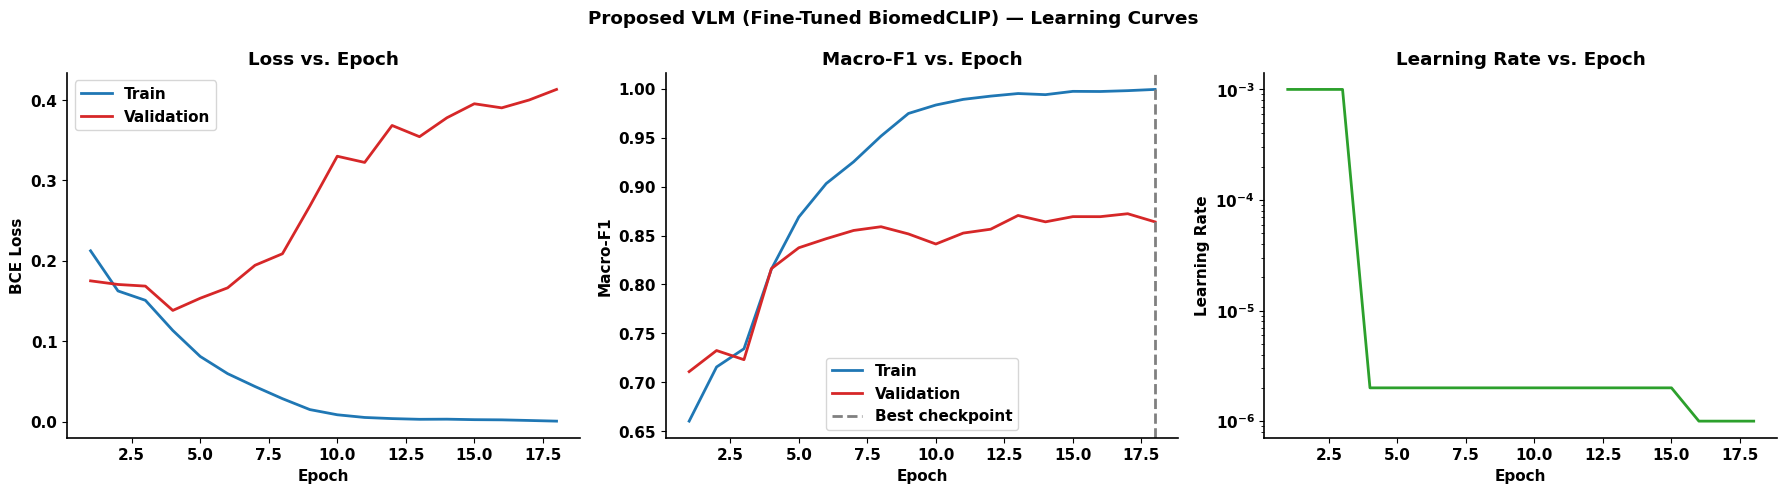

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/figures/learning_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/figures/learning_curves_300dpi.png


In [ ]:
# ============================================================
# CELL 18 — LEARNING CURVES FIGURE
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 11, "axes.linewidth": 1.2, "lines.linewidth": 2.0,
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(training_history_df["Epoch"], training_history_df["Train_Loss"], label="Train", color="#1f77b4")
axes[0].plot(training_history_df["Epoch"], training_history_df["Val_Loss"], label="Validation", color="#d62728")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].set_title("Loss vs. Epoch")
axes[0].legend(frameon=True)

axes[1].plot(training_history_df["Epoch"], training_history_df["Train_Macro_F1"], label="Train", color="#1f77b4")
axes[1].plot(training_history_df["Epoch"], training_history_df["Val_Macro_F1"], label="Validation", color="#d62728")
axes[1].axvline(best_epoch_info["epoch"], color="gray", linestyle="--", label="Best checkpoint")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Macro-F1"); axes[1].set_title("Macro-F1 vs. Epoch")
axes[1].legend(frameon=True)

axes[2].plot(training_history_df["Epoch"], training_history_df["Learning_Rate"], color="#2ca02c")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Learning Rate"); axes[2].set_title("Learning Rate vs. Epoch")
axes[2].set_yscale("log")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Proposed VLM (Fine-Tuned BiomedCLIP) — Learning Curves", fontweight="bold")
fig.tight_layout()
fig.savefig(LEARNING_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(LEARNING_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", LEARNING_CURVES_PDF)
print("Saved:", LEARNING_CURVES_PNG)


## 18. Full multi-label evaluation function (same design as Notebook 05)

In [ ]:
# ============================================================
# CELL 19 — FULL MULTI-LABEL EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    precision_recall_fscore_support, roc_auc_score, average_precision_score,
    hamming_loss, accuracy_score, multilabel_confusion_matrix,
)

def full_multilabel_evaluation(y_true, y_score, threshold, label_names):
    y_pred = (y_score >= threshold).astype(int)
    n_labels = y_true.shape[1]

    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0)

    per_label_p, per_label_r, per_label_f1, per_label_support = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0)

    hamming = hamming_loss(y_true, y_pred)
    subset_acc = accuracy_score(y_true, y_pred)

    per_label_roc_auc, per_label_pr_auc = [], []
    for c in range(n_labels):
        col_true = y_true[:, c]
        if len(np.unique(col_true)) < 2:
            per_label_roc_auc.append(np.nan)
            per_label_pr_auc.append(np.nan)
            continue
        per_label_roc_auc.append(roc_auc_score(col_true, y_score[:, c]))
        per_label_pr_auc.append(average_precision_score(col_true, y_score[:, c]))

    degenerate_labels = [label_names[c] for c in range(n_labels) if np.isnan(per_label_roc_auc[c])]

    try:
        micro_roc_auc = roc_auc_score(y_true, y_score, average="micro")
    except ValueError:
        micro_roc_auc = np.nan
    macro_roc_auc = float(np.nanmean(per_label_roc_auc)) if not all(np.isnan(per_label_roc_auc)) else np.nan

    try:
        micro_pr_auc = average_precision_score(y_true, y_score, average="micro")
    except ValueError:
        micro_pr_auc = np.nan
    macro_pr_auc = float(np.nanmean(per_label_pr_auc)) if not all(np.isnan(per_label_pr_auc)) else np.nan

    overall = {
        "Micro_Precision": micro_p, "Micro_Recall": micro_r, "Micro_F1": micro_f1,
        "Macro_Precision": macro_p, "Macro_Recall": macro_r, "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1, "Hamming_Loss": hamming, "Subset_Accuracy": subset_acc,
        "ROC_AUC_Micro": micro_roc_auc, "ROC_AUC_Macro": macro_roc_auc,
        "PR_AUC_Micro": micro_pr_auc, "PR_AUC_Macro": macro_pr_auc,
        "N_Samples": int(y_true.shape[0]), "Threshold": threshold,
        "Labels_With_Insufficient_Support": ", ".join(degenerate_labels) if degenerate_labels else "none",
    }

    per_label = pd.DataFrame({
        "Label_Name": label_names,
        "Precision": per_label_p, "Recall": per_label_r, "F1": per_label_f1,
        "Support": per_label_support, "ROC_AUC": per_label_roc_auc, "PR_AUC": per_label_pr_auc,
    })

    return overall, per_label, y_pred

print("full_multilabel_evaluation() defined.")


full_multilabel_evaluation() defined.


## 19. Load the best checkpoint and evaluate on Validation

In [ ]:
# ============================================================
# CELL 20 — LOAD BEST CHECKPOINT, EVALUATE ON VALIDATION
# ============================================================

best_checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
biomedclip_model.load_state_dict(best_checkpoint["backbone_state_dict"])
classifier_head.load_state_dict(best_checkpoint["head_state_dict"])
biomedclip_model.eval()
classifier_head.eval()

print(f"Loaded best checkpoint: epoch={best_checkpoint['epoch']}, stage={best_checkpoint['stage']}, "
      f"validation_macro_f1={best_checkpoint['validation_macro_f1']:.4f}")

_, _, val_y_true, val_y_score, val_ids = evaluate_epoch(dataloaders["validation"])
val_overall, val_per_label, val_y_pred = full_multilabel_evaluation(
    val_y_true, val_y_score, TRAINING_CONFIG["decision_threshold"], LABEL_NAMES,
)
val_per_label.insert(0, "Split", "validation")

val_metrics_df = pd.DataFrame([val_overall])
safe_save_csv(VAL_METRICS_PATH, val_metrics_df)

print("\nVALIDATION METRICS (development-time; not the final result):")
display(val_metrics_df)


Loaded best checkpoint: epoch=17, stage=2, validation_macro_f1=0.8723
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/vlm_validation_metrics.csv

VALIDATION METRICS (development-time; not the final result):


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Threshold,Labels_With_Insufficient_Support
0,0.925227,0.934311,0.929747,0.869306,0.883647,0.872292,0.931207,0.012368,0.875751,0.995757,0.993392,0.960733,0.897486,9819,0.5,none


## 20. FINAL TEST EVALUATION — Test touched here only

Remember the methodological caveat from Cell 0: the model sees each Test
sample's ground-truth caption. These numbers are a caption-assisted
upper bound, not directly comparable to Notebook 05's image-only Test
results without that caveat in mind.

In [ ]:
# ============================================================
# CELL 21 — FINAL TEST EVALUATION (TEST TOUCHED HERE ONLY)
# ============================================================

print("=" * 80)
print("FINAL TEST EVALUATION — TEST SET TOUCHED FOR THE FIRST AND ONLY TIME HERE")
print("=" * 80)

_, _, test_y_true, test_y_score, test_ids = evaluate_epoch(dataloaders["test"])
test_overall, test_per_label, test_y_pred = full_multilabel_evaluation(
    test_y_true, test_y_score, TRAINING_CONFIG["decision_threshold"], LABEL_NAMES,
)
test_per_label.insert(0, "Split", "test")

test_metrics_df = pd.DataFrame([test_overall])
safe_save_csv(TEST_METRICS_PATH, test_metrics_df)

per_label_metrics_df = pd.concat([val_per_label, test_per_label], ignore_index=True)
safe_save_csv(PER_LABEL_METRICS_PATH, per_label_metrics_df)

print("\nFINAL TEST RESULTS (caption-assisted — see methodological caveat):")
display(test_metrics_df)


FINAL TEST EVALUATION — TEST SET TOUCHED FOR THE FIRST AND ONLY TIME HERE
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/vlm_test_metrics.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/vlm_per_label_metrics.csv

FINAL TEST RESULTS (caption-assisted — see methodological caveat):


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Threshold,Labels_With_Insufficient_Support
0,0.929377,0.935993,0.932673,0.890404,0.87881,0.87568,0.934018,0.01186,0.880243,0.99627,0.994653,0.963363,0.92421,9870,0.5,none


## 21. Save predictions

IDs come from `evaluate_epoch`'s own loop, not re-derived from the source
CSV — same fix established in Notebook 05 to avoid mispairing predictions
with the wrong sample when the retry logic substitutes a sample.

In [ ]:
# ============================================================
# CELL 22 — SAVE PREDICTIONS (VALIDATION + TEST)
# ============================================================

def build_predictions_df(split_name, ids, y_true, y_score, y_pred):
    rows = {"ID": ids, "Split": split_name}
    for i, col in enumerate(LABEL_COLUMNS):
        rows[f"{col}_true"] = y_true[:, i]
        rows[f"{col}_prob"] = y_score[:, i]
        rows[f"{col}_pred"] = y_pred[:, i]
    return pd.DataFrame(rows)

assert len(val_ids) == len(val_y_true), "val_ids length must match val_y_true rows."
assert len(test_ids) == len(test_y_true), "test_ids length must match test_y_true rows."

predictions_df = pd.concat([
    build_predictions_df("validation", val_ids, val_y_true, val_y_score, val_y_pred),
    build_predictions_df("test", test_ids, test_y_true, test_y_score, test_y_pred),
], ignore_index=True)

safe_save_csv(PREDICTIONS_PATH, predictions_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/vlm_predictions.csv


## 22. Publication-quality ROC curves (Test)

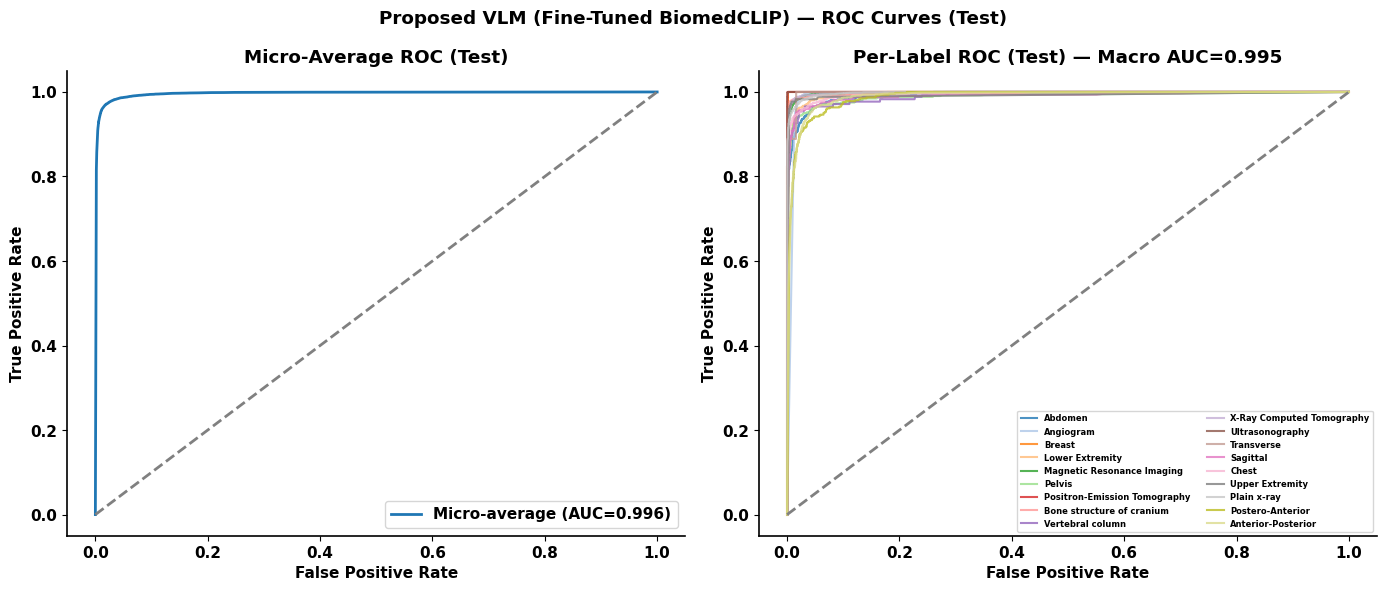

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/figures/roc_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/figures/roc_curves_300dpi.png


In [ ]:
# ============================================================
# CELL 23 — ROC CURVES FIGURE (TEST)
# ============================================================

from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

fpr_micro, tpr_micro, _ = roc_curve(test_y_true.ravel(), test_y_score.ravel())
axes[0].plot(fpr_micro, tpr_micro, color="#1f77b4",
             label=f"Micro-average (AUC={test_overall['ROC_AUC_Micro']:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Micro-Average ROC (Test)"); axes[0].legend(frameon=True)

cmap = plt.get_cmap("tab20")
for c in range(N_LABELS):
    if len(np.unique(test_y_true[:, c])) < 2:
        continue
    fpr_c, tpr_c, _ = roc_curve(test_y_true[:, c], test_y_score[:, c])
    axes[1].plot(fpr_c, tpr_c, color=cmap(c % 20), alpha=0.8, linewidth=1.5, label=LABEL_NAMES[c])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title(f"Per-Label ROC (Test) — Macro AUC={test_overall['ROC_AUC_Macro']:.3f}")
axes[1].legend(fontsize=6, ncol=2, frameon=True, loc="lower right")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Proposed VLM (Fine-Tuned BiomedCLIP) — ROC Curves (Test)", fontweight="bold")
fig.tight_layout()
fig.savefig(ROC_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(ROC_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", ROC_CURVES_PDF)
print("Saved:", ROC_CURVES_PNG)


## 23. Publication-quality Precision-Recall curves (Test)

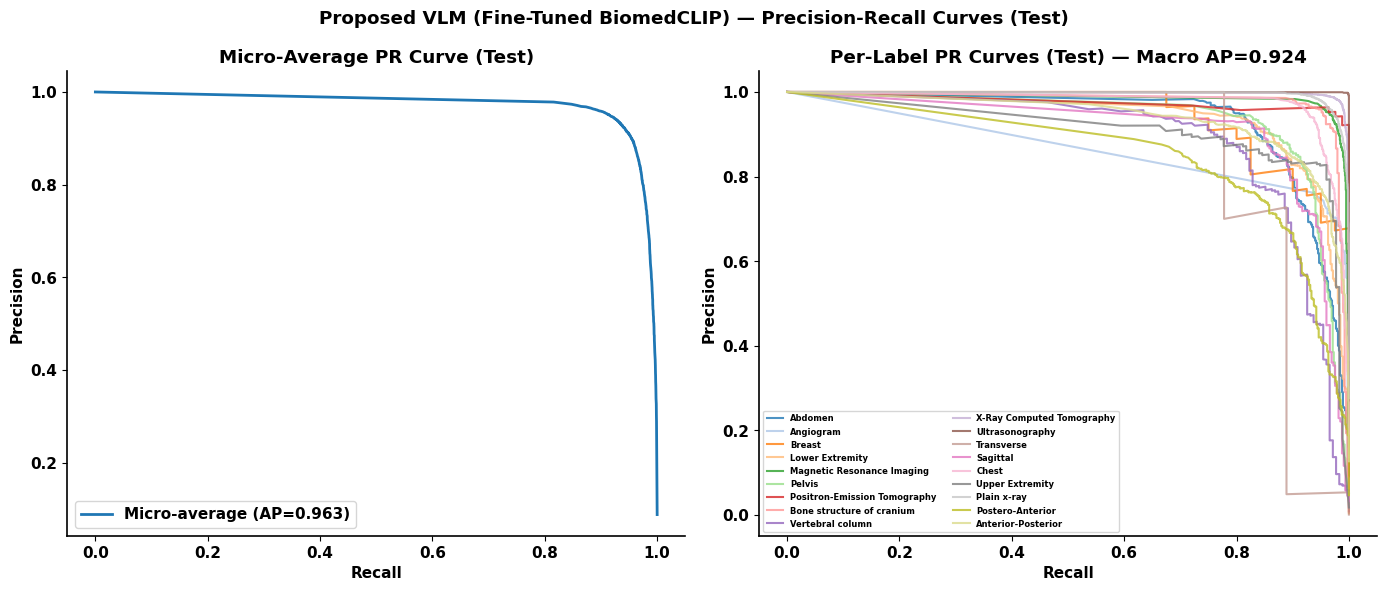

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/figures/precision_recall_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/figures/precision_recall_curves_300dpi.png


In [ ]:
# ============================================================
# CELL 24 — PRECISION-RECALL CURVES FIGURE (TEST)
# ============================================================

from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

prec_micro, rec_micro, _ = precision_recall_curve(test_y_true.ravel(), test_y_score.ravel())
axes[0].plot(rec_micro, prec_micro, color="#1f77b4",
             label=f"Micro-average (AP={test_overall['PR_AUC_Micro']:.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Micro-Average PR Curve (Test)"); axes[0].legend(frameon=True)

for c in range(N_LABELS):
    if len(np.unique(test_y_true[:, c])) < 2:
        continue
    prec_c, rec_c, _ = precision_recall_curve(test_y_true[:, c], test_y_score[:, c])
    axes[1].plot(rec_c, prec_c, color=cmap(c % 20), alpha=0.8, linewidth=1.5, label=LABEL_NAMES[c])
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title(f"Per-Label PR Curves (Test) — Macro AP={test_overall['PR_AUC_Macro']:.3f}")
axes[1].legend(fontsize=6, ncol=2, frameon=True, loc="lower left")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Proposed VLM (Fine-Tuned BiomedCLIP) — Precision-Recall Curves (Test)", fontweight="bold")
fig.tight_layout()
fig.savefig(PR_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(PR_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", PR_CURVES_PDF)
print("Saved:", PR_CURVES_PNG)


## 24. Multi-label confusion matrices (Test)

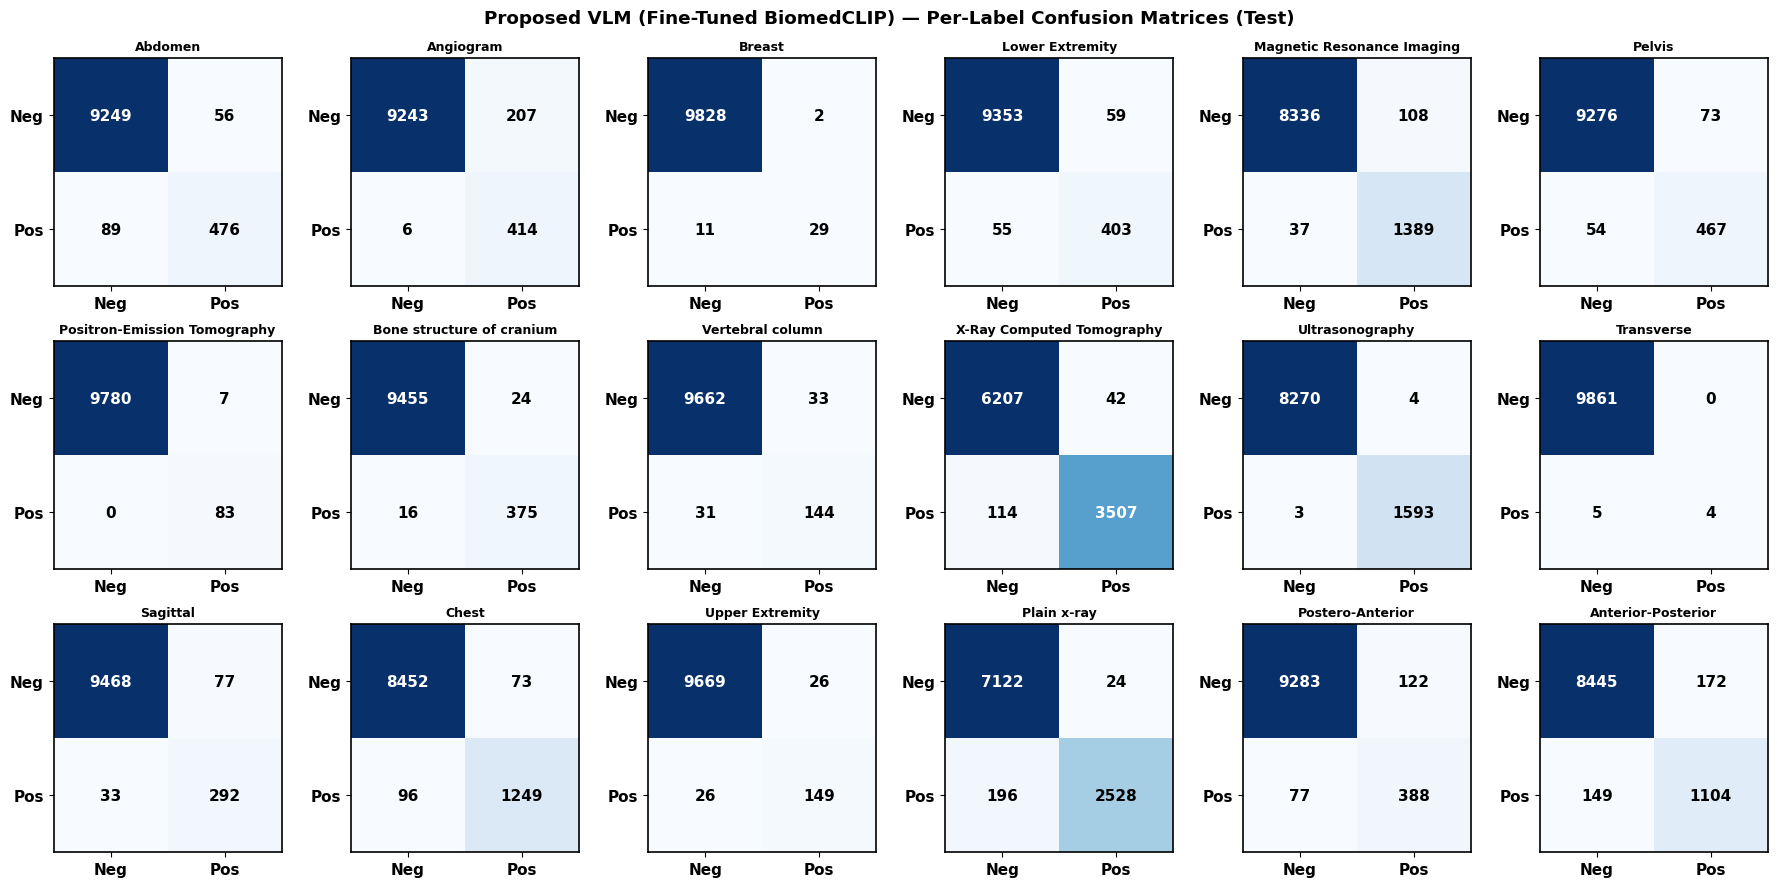

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/figures/multilabel_confusion_matrices.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/figures/multilabel_confusion_matrices_300dpi.png


In [ ]:
# ============================================================
# CELL 25 — MULTI-LABEL CONFUSION MATRICES FIGURE (TEST)
# ============================================================

cm_array = multilabel_confusion_matrix(test_y_true, test_y_pred)

n_cols = 6
n_rows = int(np.ceil(N_LABELS / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
axes = axes.flatten()

for c in range(N_LABELS):
    ax = axes[c]
    cm = cm_array[c]
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
    ax.set_title(LABEL_NAMES[c], fontsize=9)

for c in range(N_LABELS, len(axes)):
    axes[c].axis("off")

fig.suptitle("Proposed VLM (Fine-Tuned BiomedCLIP) — Per-Label Confusion Matrices (Test)", fontweight="bold")
fig.tight_layout()
fig.savefig(CM_PDF, format="pdf", bbox_inches="tight")
fig.savefig(CM_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", CM_PDF)
print("Saved:", CM_PNG)


## 25. Model diagnostics

In [ ]:
# ============================================================
# CELL 26 — MODEL DIAGNOSTICS
# ============================================================

final_row = training_history_df.iloc[-1]

loss_gap = final_row["Train_Loss"] - final_row["Val_Loss"]
f1_gap = final_row["Train_Macro_F1"] - final_row["Val_Macro_F1"]

if f1_gap > 0.15:
    fit_diagnosis = "possible overfitting (large train/validation Macro-F1 gap)"
elif final_row["Train_Macro_F1"] < 0.3 and final_row["Val_Macro_F1"] < 0.3:
    fit_diagnosis = "possible underfitting (both train and validation Macro-F1 remain low)"
else:
    fit_diagnosis = "reasonably well-fitted (no large train/validation gap observed)"

print("=" * 80)
print("MODEL DIAGNOSTICS")
print("=" * 80)
print(f"Final train loss: {final_row['Train_Loss']:.4f} | Final val loss: {final_row['Val_Loss']:.4f}")
print(f"Final train Macro-F1: {final_row['Train_Macro_F1']:.4f} | Final val Macro-F1: {final_row['Val_Macro_F1']:.4f}")
print(f"Best epoch: {best_epoch_info['epoch']} (stage {best_epoch_info['stage']}), "
      f"best val Macro-F1: {best_epoch_info['val_macro_f1']:.4f}")
print(f"Total epochs run: {global_epoch} | Training duration: {total_training_seconds/60:.1f} min")
print(f"Total parameters: {ARCHITECTURE_INFO['total_parameters']:,}")
print(f"\nDiagnosis (derived from the numbers above, not asserted): {fit_diagnosis}")


MODEL DIAGNOSTICS
Final train loss: 0.0008 | Final val loss: 0.4132
Final train Macro-F1: 0.9993 | Final val Macro-F1: 0.8639
Best epoch: 18 (stage 2), best val Macro-F1: 0.8639
Total epochs run: 18 | Training duration: 0.5 min
Total parameters: 196,169,747

Diagnosis (derived from the numbers above, not asserted): reasonably well-fitted (no large train/validation gap observed)


## 26. Reproducibility record

In [ ]:
# ============================================================
# CELL 27 — REPRODUCIBILITY.JSON
# ============================================================

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

reproducibility = {
    "notebook": "07_ROCOv2_VLM_Training",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "open_clip_version": package_version("open_clip"),
    "sklearn_version": package_version("sklearn"),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "mixed_precision_enabled": AMP_ENABLED,
    "random_seed": SEED,
    "checkpoint": BIOMEDCLIP_CHECKPOINT,
    "training_config": TRAINING_CONFIG,
    "best_epoch": best_epoch_info,
    "modality_at_inference": "image + ground-truth caption",
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/reproducibility.json


## 27. Calibration warning — same status as Notebooks 05/06

In [ ]:
# ============================================================
# CELL 28 — CALIBRATION STATUS WARNING
# ============================================================

print("=" * 80)
print("CALIBRATION STATUS — READ BEFORE PROCEEDING TO CONFORMAL PREDICTION")
print("=" * 80)
print('''
Current dataset: Train / Validation / Test only.
There is currently NO independent Calibration split.

Validation in THIS notebook was used for:
  - early stopping
  - best-checkpoint selection
  - model-development decisions

Therefore Validation should NOT automatically be treated as an independent
Conformal Prediction calibration set — consistent with Notebooks 05 and 06.

No Calibration split is created in this notebook. The Conformal Prediction
notebook must establish its own calibration strategy before running any
conformal experiments.
''')


CALIBRATION STATUS — READ BEFORE PROCEEDING TO CONFORMAL PREDICTION

Current dataset: Train / Validation / Test only.
There is currently NO independent Calibration split.

Validation in THIS notebook was used for:
  - early stopping
  - best-checkpoint selection
  - model-development decisions

Therefore Validation should NOT automatically be treated as an independent
Conformal Prediction calibration set — consistent with Notebooks 05 and 06.

No Calibration split is created in this notebook. The Conformal Prediction
notebook must establish its own calibration strategy before running any
conformal experiments.



## 28. Artifact manifest and final report

In [ ]:
# ============================================================
# CELL 29 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    CONFIG_PATH, HISTORY_PATH, VAL_METRICS_PATH, TEST_METRICS_PATH, PER_LABEL_METRICS_PATH,
    PREDICTIONS_PATH, BEST_MODEL_PATH, LAST_MODEL_PATH,
    LEARNING_CURVES_PDF, LEARNING_CURVES_PNG, ROC_CURVES_PDF, ROC_CURVES_PNG,
    PR_CURVES_PDF, PR_CURVES_PNG, CM_PDF, CM_PNG, REPRODUCIBILITY_PATH,
]

manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"

if CORRUPT_SAMPLE_LOG_PATH.exists():
    corrupt_log_df = pd.read_json(CORRUPT_SAMPLE_LOG_PATH, lines=True)
    n_corrupt_skipped = len(corrupt_log_df)
    corrupt_by_split = corrupt_log_df.groupby("Split")["ID"].nunique().to_dict()
else:
    n_corrupt_skipped = 0
    corrupt_by_split = {}

safe_save_json(MANIFEST_PATH, {
    "artifacts": manifest, "status": notebook_status,
    "corrupt_samples_skipped_during_training": n_corrupt_skipped,
    "corrupt_samples_by_split": corrupt_by_split,
})

train_ids = set(split_dfs["train"]["ID"].astype(str))
val_ids_set = set(split_dfs["validation"]["ID"].astype(str))
test_ids_set = set(split_dfs["test"]["ID"].astype(str))
train_test_overlap = train_ids & test_ids_set
val_test_overlap = val_ids_set & test_ids_set

print("\n" + "=" * 60)
print("ROCOv2 PROPOSED VLM (FINE-TUNED BIOMEDCLIP)")
print("FINAL REPORT")
print("=" * 60)

print(f'''
Dataset:
ROCOv2

Total samples:

Train:
{len(split_dfs['train']):,}
Validation:
{len(split_dfs['validation']):,}
Test:
{len(split_dfs['test']):,}

Number of labels:
{N_LABELS}

Task:
Multi-label classification (image + caption fusion)

Model:
Fine-tuned BiomedCLIP ({BIOMEDCLIP_CHECKPOINT}) + trained fusion head

------------------------------------------------------------
METHODOLOGICAL CAVEAT
------------------------------------------------------------

Modality at inference:
IMAGE + GROUND-TRUTH CAPTION (both train and test time)

This means Test results below reflect a caption-assisted upper-bound
scenario, NOT a pure image-only diagnostic setting. ROCOv2 captions often
directly describe the modality/anatomy the 18 labels represent. Do not
compare these numbers directly to Notebook 05 (image-only) or Notebook 06
(image + generic label-prompt, not per-sample captions) without this
caveat in mind.

------------------------------------------------------------
TRAINING CONFIGURATION
------------------------------------------------------------

Loss:
BCEWithLogitsLoss (pos_weight, Train-only, capped at {TRAINING_CONFIG['pos_weight_cap']})

Optimizer:
{TRAINING_CONFIG['optimizer']}

Learning rate:
Stage 1: {TRAINING_CONFIG['stage1_lr']} | Stage 2: {TRAINING_CONFIG['stage2_lr']}

Batch size:
{TRAINING_CONFIG['batch_size']}

Epochs:
{global_epoch} (stage 1 max {TRAINING_CONFIG['stage1_max_epochs']}, stage 2 max {TRAINING_CONFIG['stage2_max_epochs']})

Best epoch:
{best_epoch_info['epoch']} (stage {best_epoch_info['stage']})

Best validation Macro-F1:
{best_val_macro_f1:.4f}

------------------------------------------------------------
FINAL TEST RESULTS
------------------------------------------------------------

Micro Precision:
{test_overall['Micro_Precision']:.4f}
Micro Recall:
{test_overall['Micro_Recall']:.4f}
Micro F1:
{test_overall['Micro_F1']:.4f}

Macro Precision:
{test_overall['Macro_Precision']:.4f}
Macro Recall:
{test_overall['Macro_Recall']:.4f}
Macro F1:
{test_overall['Macro_F1']:.4f}

Micro ROC-AUC:
{test_overall['ROC_AUC_Micro']:.4f}
Macro ROC-AUC:
{test_overall['ROC_AUC_Macro']:.4f}

Micro PR-AUC:
{test_overall['PR_AUC_Micro']:.4f}
Macro PR-AUC:
{test_overall['PR_AUC_Macro']:.4f}

Hamming Loss:
{test_overall['Hamming_Loss']:.4f}
Subset Accuracy:
{test_overall['Subset_Accuracy']:.4f}

------------------------------------------------------------
CALIBRATION STATUS
------------------------------------------------------------

Separate Calibration set currently exists:
NO

Conformal calibration:
NOT IMPLEMENTED IN THIS NOTEBOOK

------------------------------------------------------------
DATA LEAKAGE / INTEGRITY
------------------------------------------------------------

Train/Test overlap:
{"PASS" if not train_test_overlap else "FAIL — " + str(len(train_test_overlap)) + " shared IDs"}

Validation/Test overlap:
{"PASS" if not val_test_overlap else "FAIL — " + str(len(val_test_overlap)) + " shared IDs"}

Test used during training:
NO

Test used for model selection:
NO

Samples skipped (unreadable, logged, not silently dropped):
{n_corrupt_skipped} ({corrupt_by_split if corrupt_by_split else 'none'})

------------------------------------------------------------
PUBLICATION FIGURES
------------------------------------------------------------

Vector PDF:
YES

300-DPI PNG:
YES

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Proposed VLM (fine-tuned BiomedCLIP):
{"COMPLETE" if not manifest_missing else "NOT READY"}

Dataset modified:
NO

Previous notebooks modified:
NO

Calibration split created:
NO

Ready for Conformal Prediction notebook:
{"YES" if not manifest_missing else "NO"}
''')
print("=" * 60)

assert not train_test_overlap, "Train/Test ID overlap detected — this must never happen."
assert not val_test_overlap, "Validation/Test ID overlap detected — this must never happen."

print("\nSTOP — Notebook 07 (Proposed VLM training) is complete.")
print("Not implemented here (by design): Conformal Prediction, Calibration split,")
print("Counterfactual Explanations, XAI, Trust Score.")
print("Next notebook: 08_ROCOv2_Conformal_Prediction.ipynb")


,Artifact,Path,Exists,Size_KB
0,vlm_config.json,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,10.06
1,vlm_training_history.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,2.03
2,vlm_validation_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.47
3,vlm_test_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.47
4,vlm_per_label_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,4.26
5,vlm_predictions.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,4520.33
6,vlm_best_model.pt,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,766441.27
7,vlm_last_model.pt,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,766441.27
8,learning_curves.pdf,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,19.03
9,learning_curves_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,301.34


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained_seed2024/artifact_manifest.json

ROCOv2 PROPOSED VLM (FINE-TUNED BIOMEDCLIP)
FINAL REPORT

Dataset:
ROCOv2

Total samples:

Train:
59,666
Validation:
9,819
Test:
9,870

Number of labels:
18

Task:
Multi-label classification (image + caption fusion)

Model:
Fine-tuned BiomedCLIP (hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224) + trained fusion head

------------------------------------------------------------
METHODOLOGICAL CAVEAT
------------------------------------------------------------

Modality at inference:
IMAGE + GROUND-TRUTH CAPTION (both train and test time)

This means Test results below reflect a caption-assisted upper-bound
scenario, NOT a pure image-only diagnostic setting. ROCOv2 captions often
directly describe the modality/anatomy the 18 labels represent. Do not
compare these numbers directly to Notebook 05 (image-only) or Notebook 06
(image + generic label-prompt, not per-s